# Mobility entropy

## Destinations reached by origin population

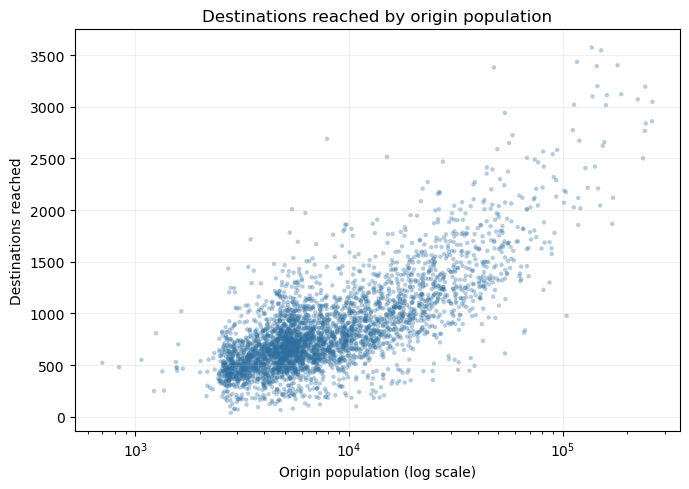

3,741 origins


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

SAVE = {"income_diversity", "s50_defense", "ses_formula"}  # section names to write PNGs for; empty set = write none


def save(fig, name, section=None):
    if section is None or section in SAVE:
        fig.savefig(Path.home() / "Desktop" / name, dpi=180, bbox_inches="tight")


ROOT = Path.cwd().resolve()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
DATA = ROOT / "data"

pairs = pd.read_parquet(
    DATA / "recent_2025-03" / "_od_pairs_cache.parquet",
    columns=["id_origin", "id_destination", "n_trips"],
)
pairs[["id_origin", "id_destination"]] = pairs[["id_origin", "id_destination"]].astype(str)
pairs = pairs[
    pairs["id_origin"].str[0].str.isdigit()
    & pairs["id_destination"].str[0].str.isdigit()
    & (pairs["id_origin"] != pairs["id_destination"])
    & (pairs["n_trips"] > 0)
]

destinations = pairs.groupby("id_origin")["id_destination"].nunique()

crosswalk = pd.read_csv(
    DATA / "geometries" / "relacion_ine_zonificacionMitma.csv",
    sep="|",
    dtype=str,
)
population = pd.read_csv(
    DATA / "demo" / "pop_seccion_2023.csv",
    dtype={"seccion_ine": str},
)
population = (
    crosswalk[["seccion_ine", "distrito_mitma"]]
    .merge(population, on="seccion_ine", how="left")
    .groupby("distrito_mitma")["poblacion"]
    .sum(min_count=1)
)

origins = (
    destinations.rename("destinations")
    .to_frame()
    .join(population.rename("population"))
    .dropna()
)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(
    origins["population"],
    origins["destinations"],
    s=10,
    alpha=0.35,
    color="#2f6f9f",
    edgecolors="none",
)
ax.set_xscale("log")
ax.set_xlabel("Origin population (log scale)")
ax.set_ylabel("Destinations reached")
ax.set_title("Destinations reached by origin population")
ax.grid(alpha=0.2)
fig.tight_layout()

save(fig, "origin_destinations_by_population.png", "measure1")
plt.show()
print(f"{len(origins):,} origins")

## Rank–share curve: Madrid Centro

Destinations ranked by trip volume, each as a share of the origin's outgoing trips.

Madrid Centro        dests=3,572  H=3.718  effective= 41.2
Llanes (Asturias)    dests=1,211  H=3.712  effective= 40.9


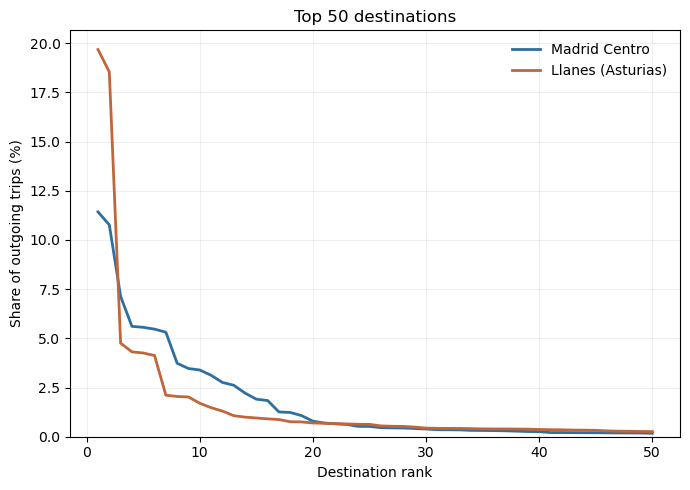

In [2]:
import numpy as np

TOP = 50
DISTRICTS = {"Madrid Centro": "2807901", "Llanes (Asturias)": "33036"}


def shares(origin):
    flows = (
        pairs.loc[pairs["id_origin"] == origin, "n_trips"]
        .sort_values(ascending=False)
        .to_numpy()
    )
    return flows / flows.sum()


fig, ax = plt.subplots(figsize=(7, 5))
for (name, origin), color in zip(DISTRICTS.items(), ["#2f6f9f", "#c1663a"]):
    s = shares(origin)
    ax.plot(np.arange(1, TOP + 1), s[:TOP] * 100, lw=2, color=color, label=name)
    H = -(s * np.log(s)).sum()
    print(f"{name:20s} dests={len(s):5,d}  H={H:.3f}  effective={np.exp(H):5.1f}")

ax.set_xlabel("Destination rank")
ax.set_ylabel("Share of outgoing trips (%)")
ax.set_title(f"Top {TOP} destinations")
ax.set_ylim(0)
ax.legend(frameon=False)
ax.grid(alpha=0.2)
fig.tight_layout()

save(fig, "rank_share_comparison.png", "measure1")
plt.show()

## 1. H — raw entropy

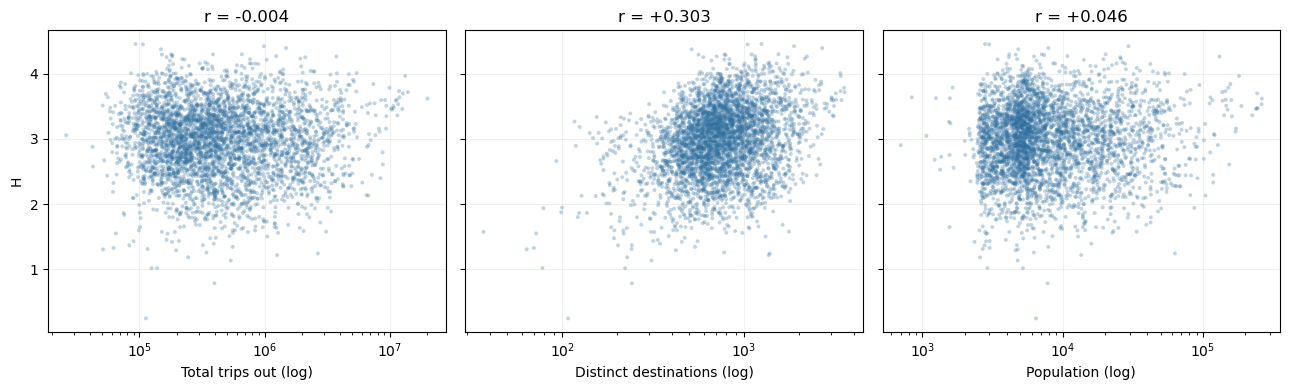

min    0.245
50%    3.000
max    4.456


In [3]:
totals = pairs.groupby("id_origin")["n_trips"].transform("sum")
p = pairs["n_trips"] / totals
grouped = pairs.assign(term=-p * np.log(p)).groupby("id_origin")

entropy = pd.DataFrame(
    {
        "H": grouped["term"].sum(),
        "trips": grouped["n_trips"].sum(),
        "destinations": grouped.size(),
    }
).join(population.rename("population"))

panels = [
    ("trips", "Total trips out (log)"),
    ("destinations", "Distinct destinations (log)"),
    ("population", "Population (log)"),
]

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (col, label) in zip(axes, panels):
    d = entropy[["H", col]].dropna()
    ax.scatter(d[col], d["H"], s=8, alpha=0.3, color="#2f6f9f", edgecolors="none")
    ax.set_xscale("log")
    ax.set_xlabel(label)
    ax.set_title(f"r = {np.corrcoef(np.log(d[col]), d['H'])[0, 1]:+.3f}")
    ax.grid(alpha=0.2)

axes[0].set_ylabel("H")
fig.tight_layout()
save(fig, "entropy_1_H.png", "measure1")
plt.show()
print(entropy["H"].describe()[["min", "50%", "max"]].round(3).to_string())

## 2. S — normalised by observed destinations

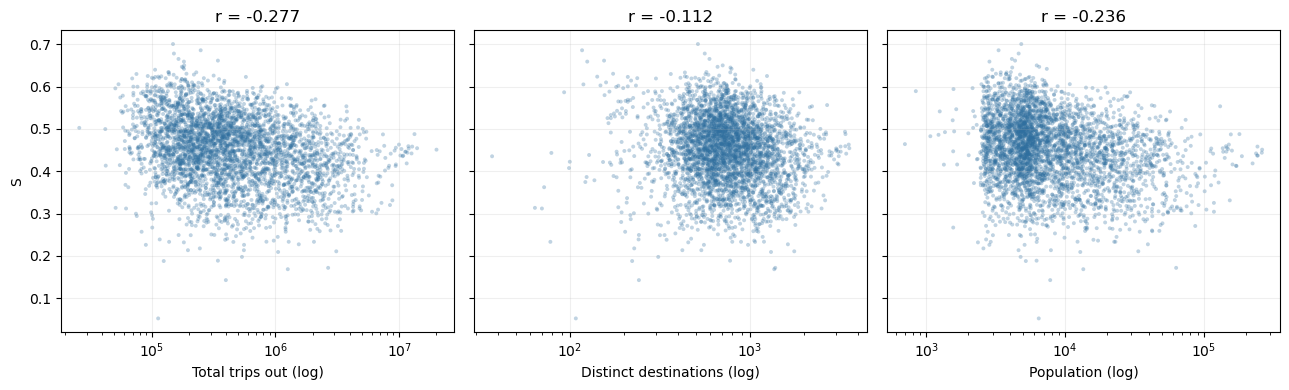

min    0.052
50%    0.455
max    0.701


In [4]:
entropy["S"] = entropy["H"] / np.log(entropy["destinations"])

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (col, label) in zip(axes, panels):
    d = entropy[["S", col]].dropna()
    ax.scatter(d[col], d["S"], s=8, alpha=0.3, color="#2f6f9f", edgecolors="none")
    ax.set_xscale("log")
    ax.set_xlabel(label)
    ax.set_title(f"r = {np.corrcoef(np.log(d[col]), d['S'])[0, 1]:+.3f}")
    ax.grid(alpha=0.2)

axes[0].set_ylabel("S")
fig.tight_layout()
save(fig, "entropy_2_S.png", "measure1")
plt.show()
print(entropy["S"].describe()[["min", "50%", "max"]].round(3).to_string())

## Why H and not S

Income correlates with trip volume, and S carries a volume artifact that works against it.

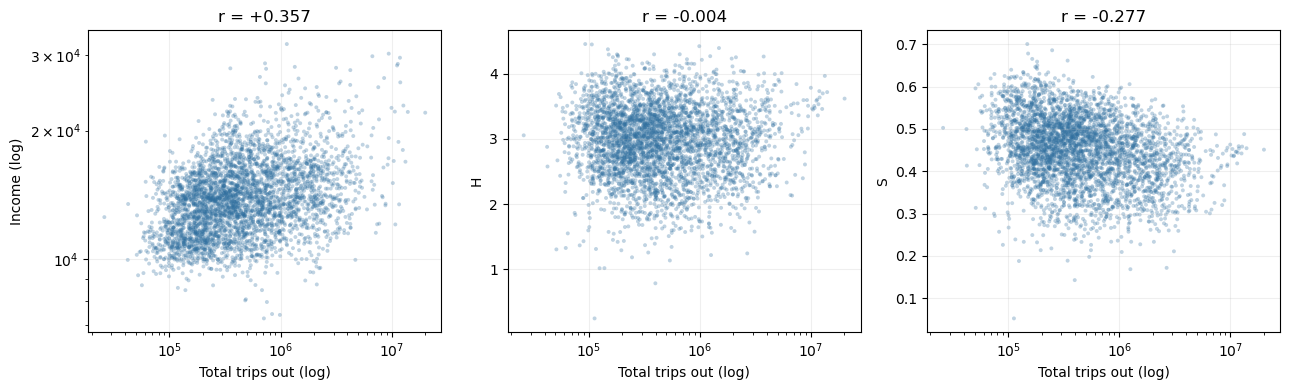

H vs log income  r = +0.165
S vs log income  r = +0.057


In [5]:
income = pd.read_csv(DATA / "renta" / "renta_seccion_2023.csv", dtype={"seccion_ine": str})
sections = (
    crosswalk[["seccion_ine", "distrito_mitma"]]
    .merge(income, on="seccion_ine")
    .merge(
        pd.read_csv(DATA / "demo" / "pop_seccion_2023.csv", dtype={"seccion_ine": str}),
        on="seccion_ine",
    )
)
sections["weighted"] = sections["renta_persona"] * sections["poblacion"]
districts = sections.groupby("distrito_mitma").agg(
    income=("weighted", "sum"), pop=("poblacion", "sum")
)
districts["income"] /= districts["pop"]

d = entropy.join(districts["income"]).dropna(subset=["income", "H", "S"])
d = d[d["income"] > 0]

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
plots = [
    ("income", "Income (log)", True),
    ("H", "H", False),
    ("S", "S", False),
]
for ax, (col, label, logy) in zip(axes, plots):
    ax.scatter(d["trips"], d[col], s=8, alpha=0.3, color="#2f6f9f", edgecolors="none")
    ax.set_xscale("log")
    if logy:
        ax.set_yscale("log")
    ax.set_xlabel("Total trips out (log)")
    ax.set_ylabel(label)
    y = np.log(d[col]) if logy else d[col]
    ax.set_title(f"r = {np.corrcoef(np.log(d['trips']), y)[0, 1]:+.3f}")
    ax.grid(alpha=0.2)

fig.tight_layout()
save(fig, "why_H_not_S.png", "measure1")
plt.show()

li = np.log(d["income"])
print(f"H vs log income  r = {np.corrcoef(d['H'], li)[0, 1]:+.3f}")
print(f"S vs log income  r = {np.corrcoef(d['S'], li)[0, 1]:+.3f}")

## H against income

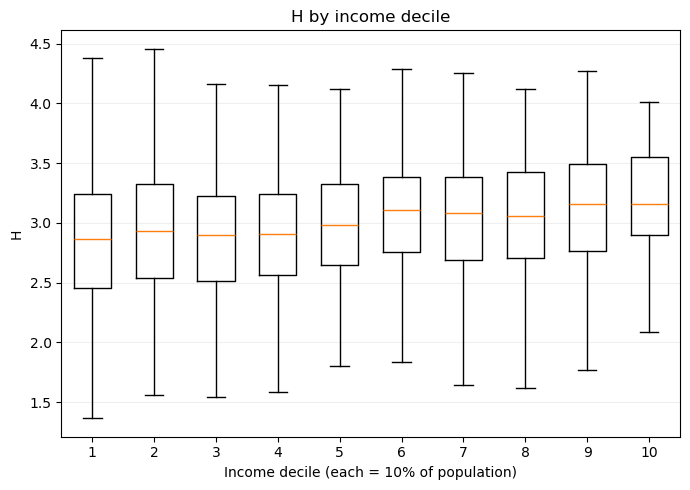

          income     H  districts
decile                           
1       10562.84  2.87        575
2       11602.78  2.93        421
3       12518.84  2.90        417
4       13206.15  2.90        361
5       13868.30  2.98        390
6       14596.78  3.11        419
7       15537.15  3.08        351
8       16479.69  3.06        328
9       18059.98  3.16        295
10      21263.71  3.16        183


In [6]:
d = d.join(districts["pop"])
order = d["income"].sort_values().index
cumulative_pop = d.loc[order, "pop"].cumsum() / d["pop"].sum()
d["decile"] = (
    pd.cut(cumulative_pop, np.linspace(0, 1, 11), labels=range(1, 11))
    .reindex(d.index)
    .astype("Int64")
)

fig, ax = plt.subplots(figsize=(7, 5))
groups = [d.loc[d["decile"] == i, "H"].dropna() for i in range(1, 11)]
ax.boxplot(groups, positions=range(1, 11), widths=0.6, showfliers=False)
ax.set_xlabel("Income decile (each = 10% of population)")
ax.set_ylabel("H")
ax.set_title("H by income decile")
ax.grid(alpha=0.2, axis="y")
fig.tight_layout()
save(fig, "H_by_income_decile.png", "measure1")
plt.show()

print(
    d.groupby("decile", observed=True)
    .agg(income=("income", "median"), H=("H", "median"), districts=("H", "size"))
    .round(2)
    .to_string()
)

## H against unemployment

Paro is municipality-level; allocated to sections by working-age share, then summed to districts. Rate uses working-age population as denominator. Districts with any municipality missing paro are dropped.

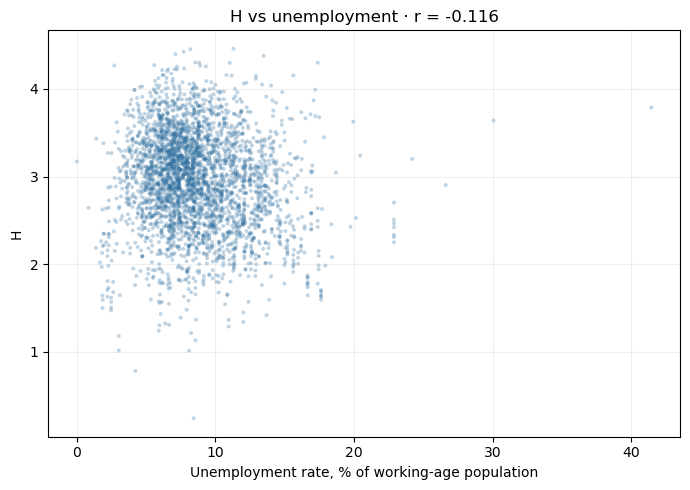

n = 3,269   R2 = 0.0305
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.5910      0.505     -1.171      0.242      -1.581       0.399
u             -1.0561      0.322     -3.281      0.001      -1.687      -0.425
log_income     0.3630      0.053      6.836      0.000       0.259       0.467
log_pop        0.0197      0.012      1.671      0.095      -0.003       0.043


In [7]:
import statsmodels.api as sm

paro = pd.read_csv(DATA / "paro" / "paro_municipios_2025-03.csv", dtype={"municipio_ine": str})
working_age = pd.read_csv(
    DATA / "demo" / "workingage_seccion_2023.csv", dtype={"seccion_ine": str}
)

s = crosswalk[["seccion_ine", "municipio_ine", "distrito_mitma"]].merge(
    working_age, on="seccion_ine", how="left"
)
s["muni_paro"] = s["municipio_ine"].map(paro.set_index("municipio_ine")["total_paro"])
s["muni_wa"] = s["municipio_ine"].map(
    s.groupby("municipio_ine")["working_age_pop"].sum(min_count=1)
)
s["allocated"] = s["muni_paro"] * s["working_age_pop"] / s["muni_wa"]

unemployment = s.groupby("distrito_mitma").agg(
    paro=("allocated", "sum"), working_age=("working_age_pop", "sum")
)
unemployment.loc[s.groupby("distrito_mitma")["allocated"].apply(lambda x: x.isna().any()), "paro"] = np.nan
unemployment["u"] = unemployment["paro"] / unemployment["working_age"]

u = d.join(unemployment["u"]).dropna(subset=["u", "H", "income", "pop"])

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(u["u"] * 100, u["H"], s=8, alpha=0.3, color="#2f6f9f", edgecolors="none")
ax.set_xlabel("Unemployment rate, % of working-age population")
ax.set_ylabel("H")
ax.set_title(f"H vs unemployment · r = {np.corrcoef(u['u'], u['H'])[0, 1]:+.3f}")
ax.grid(alpha=0.2)
fig.tight_layout()
save(fig, "H_vs_unemployment.png", "measure1")
plt.show()

X = pd.DataFrame(
    {"u": u["u"], "log_income": np.log(u["income"]), "log_pop": np.log(u["pop"])}
)
model = sm.OLS(u["H"], sm.add_constant(X)).fit()
print(f"n = {len(u):,}   R2 = {model.rsquared:.4f}")
print(model.summary().tables[1])

## Same analysis with S

Decile plot, unemployment scatter, and both regressions repeated with S in place of H.

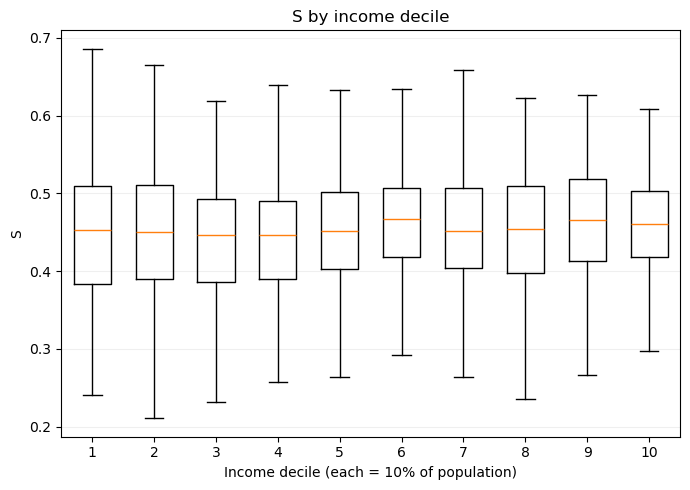

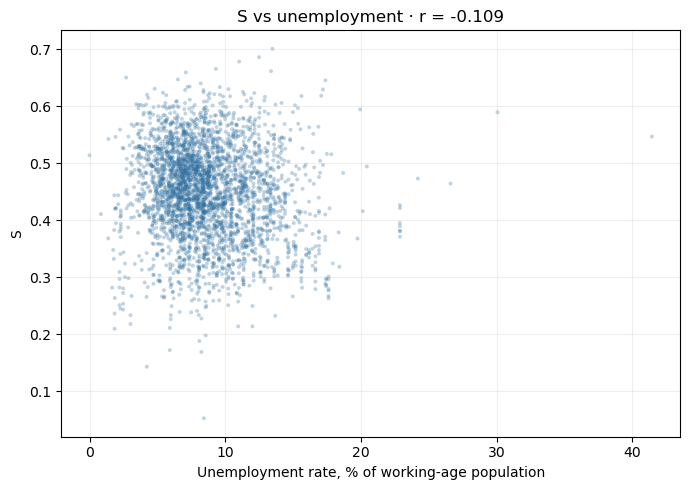

--- S ~ income model · n = 3,740 · R2 = 0.0667
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.2623      0.060      4.352      0.000       0.144       0.381
log_income     0.0424      0.006      6.585      0.000       0.030       0.055
log_pop       -0.0241      0.002    -15.931      0.000      -0.027      -0.021
--- S ~ unemployment model · n = 3,269 · R2 = 0.0671
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.3536      0.073      4.873      0.000       0.211       0.496
u             -0.1503      0.046     -3.249      0.001      -0.241      -0.060
log_income     0.0335      0.008      4.387      0.000       0.019       0.048
log_pop       -0.0235      0.002    -13.851      0.000      -0.027      -0.020


In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.boxplot(
    [d.loc[d["decile"] == i, "S"].dropna() for i in range(1, 11)],
    positions=range(1, 11),
    widths=0.6,
    showfliers=False,
)
ax.set_xlabel("Income decile (each = 10% of population)")
ax.set_ylabel("S")
ax.set_title("S by income decile")
ax.grid(alpha=0.2, axis="y")
fig.tight_layout()
save(fig, "S_by_income_decile.png", "measure1")
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(u["u"] * 100, u["S"], s=8, alpha=0.3, color="#2f6f9f", edgecolors="none")
ax.set_xlabel("Unemployment rate, % of working-age population")
ax.set_ylabel("S")
ax.set_title(f"S vs unemployment · r = {np.corrcoef(u['u'], u['S'])[0, 1]:+.3f}")
ax.grid(alpha=0.2)
fig.tight_layout()
save(fig, "S_vs_unemployment.png", "measure1")
plt.show()

fits = {
    "income": sm.OLS(
        d["S"], sm.add_constant(pd.DataFrame({"log_income": np.log(d["income"]), "log_pop": np.log(d["pop"])}))
    ).fit(),
    "unemployment": sm.OLS(
        u["S"],
        sm.add_constant(
            pd.DataFrame({"u": u["u"], "log_income": np.log(u["income"]), "log_pop": np.log(u["pop"])})
        ),
    ).fit(),
}
for name, fit in fits.items():
    print(f"--- S ~ {name} model · n = {int(fit.nobs):,} · R2 = {fit.rsquared:.4f}")
    print(fit.summary().tables[1])

## 3. S50 — normalised by available destinations within 50 km

Both numerator and denominator restricted to the same set: shares recomputed over
destinations within 50 km, denominator is the count of zones within 50 km from geometry.

In [9]:
import geopandas as gpd
from scipy.spatial import cKDTree

RADIUS_KM = 50

zones = gpd.read_file(DATA / "geometries" / "zonificacion_distritos.shp").set_index("ID")
centroids = zones.geometry.centroid
xy = np.c_[centroids.x, centroids.y]
tree = cKDTree(xy)

neighbours = tree.query_ball_point(xy, RADIUS_KM * 1000)
n_avail = pd.Series(
    [len(n) - 1 for n in neighbours], index=zones.index, name="n_avail"
)

within = pd.DataFrame(
    [(zones.index[i], zones.index[j]) for i, ns in enumerate(neighbours) for j in ns],
    columns=["id_origin", "id_destination"],
)
local = pairs.merge(within, on=["id_origin", "id_destination"])

local_totals = local.groupby("id_origin")["n_trips"].transform("sum")
q = local["n_trips"] / local_totals
H50 = local.assign(term=-q * np.log(q)).groupby("id_origin")["term"].sum()

entropy["H50"] = H50
entropy["n_avail"] = n_avail
entropy["S50"] = entropy["H50"] / np.log(entropy["n_avail"])

print(f"trips kept within {RADIUS_KM} km: {100 * local['n_trips'].sum() / pairs['n_trips'].sum():.1f}%")
print(f"n_avail  min={n_avail.min()}  median={int(n_avail.median())}  max={n_avail.max()}")
print(f"zones with n_avail < 2: {(n_avail < 2).sum()}")
print(entropy[["H", "S", "S50"]].describe().loc[["min", "50%", "max"]].round(3).to_string())

  return ogr_read(


trips kept within 50 km: 96.8%
n_avail  min=0  median=64  max=310
zones with n_avail < 2: 104
         H      S    S50
min  0.245  0.052  0.214
50%  3.000  0.455  0.634
max  4.456  0.701  0.951


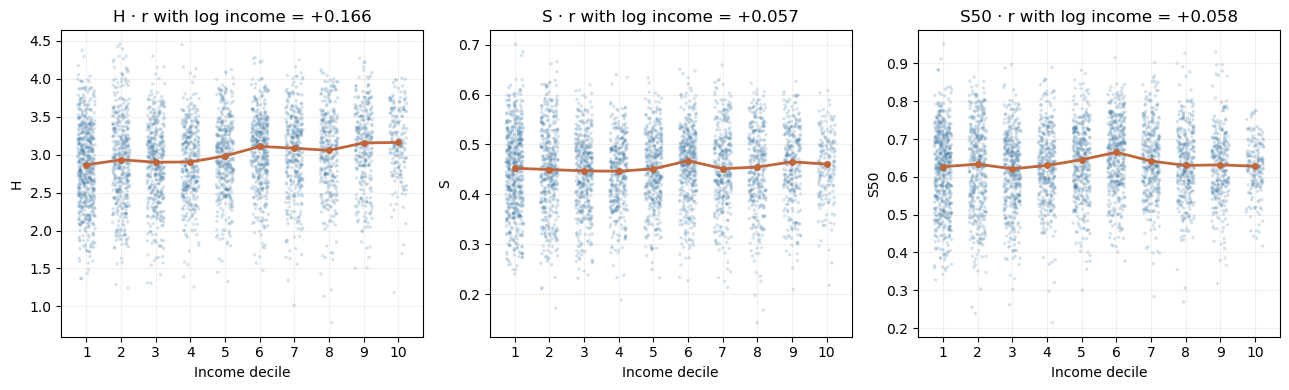

           income      H      S    S50
decile                                
1       10562.838  2.866  0.452  0.627
2       11602.776  2.933  0.450  0.634
3       12520.111  2.901  0.447  0.621
4       13206.150  2.905  0.446  0.630
5       13868.304  2.983  0.451  0.645
6       14592.120  3.110  0.467  0.665
7       15537.145  3.085  0.452  0.642
8       16479.689  3.058  0.455  0.630
9       18059.977  3.156  0.465  0.632
10      21263.715  3.161  0.461  0.628


In [10]:
c = d.join(entropy[["S50"]]).dropna(subset=["S50", "decile"])

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, ["H", "S", "S50"]):
    ax.scatter(
        c["decile"] + np.random.uniform(-0.25, 0.25, len(c)),
        c[col],
        s=6,
        alpha=0.2,
        color="#2f6f9f",
        edgecolors="none",
    )
    medians = c.groupby("decile", observed=True)[col].median()
    ax.plot(medians.index, medians.values, color="#c1663a", lw=2, marker="o", ms=4)
    ax.set_xlabel("Income decile")
    ax.set_ylabel(col)
    ax.set_xticks(range(1, 11))
    r = np.corrcoef(np.log(c["income"]), c[col])[0, 1]
    ax.set_title(f"{col} · r with log income = {r:+.3f}")
    ax.grid(alpha=0.2)

fig.tight_layout()
save(fig, "H_S_S50_by_income_decile.png", "measure1")
plt.show()

print(
    c.groupby("decile", observed=True)
    .agg(income=("income", "median"), H=("H", "median"), S=("S", "median"), S50=("S50", "median"))
    .round(3)
    .to_string()
)

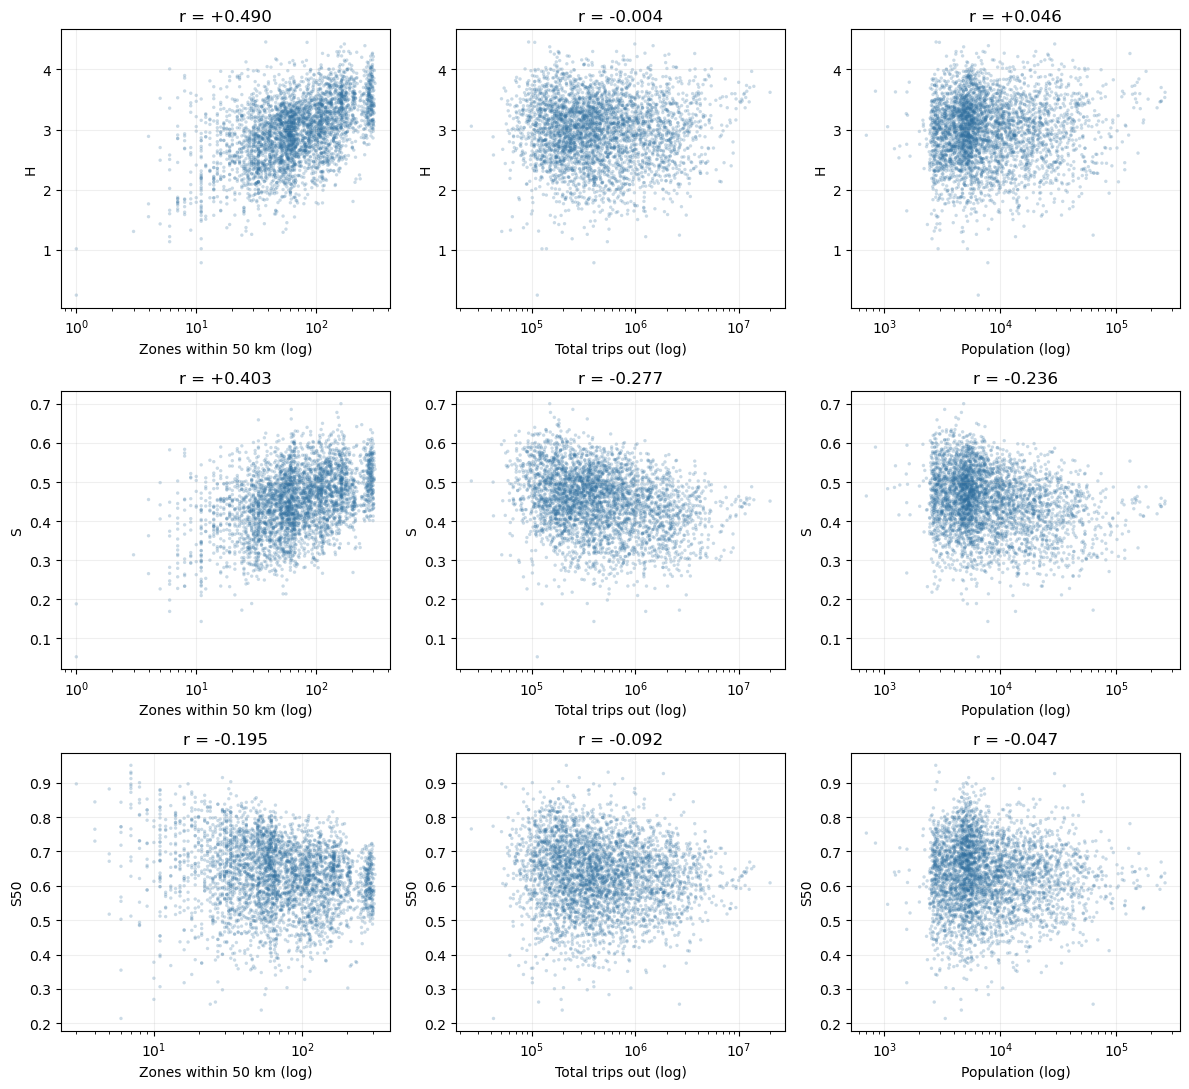

In [11]:
e = entropy.replace([np.inf, -np.inf], np.nan)
confounds = [
    ("n_avail", "Zones within 50 km (log)"),
    ("trips", "Total trips out (log)"),
    ("population", "Population (log)"),
]

fig, axes = plt.subplots(3, 3, figsize=(12, 11))
for row, measure in zip(axes, ["H", "S", "S50"]):
    for ax, (col, label) in zip(row, confounds):
        x = e[[col, measure]].dropna()
        x = x[x[col] > 0]
        ax.scatter(x[col], x[measure], s=6, alpha=0.25, color="#2f6f9f", edgecolors="none")
        ax.set_xscale("log")
        ax.set_xlabel(label)
        ax.set_ylabel(measure)
        ax.set_title(f"r = {np.corrcoef(np.log(x[col]), x[measure])[0, 1]:+.3f}")
        ax.grid(alpha=0.2)

fig.tight_layout()
save(fig, "confounds_H_S_S50.png", "measure1")
plt.show()

## Why S50, before looking at income

Three checks on the measures themselves, none of them using income or unemployment.


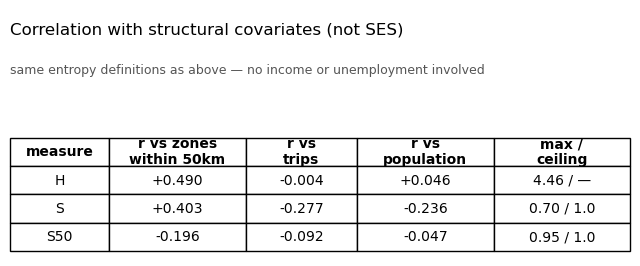

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.axis("off")
ax.text(0, 0.95, "Correlation with structural covariates (not SES)", fontsize=12, va="top")
ax.text(0, 0.78, "same entropy definitions as above — no income or unemployment involved", fontsize=9, va="top", color="#555555")

rows = []
for name in ["H", "S", "S50"]:
    x = e[["n_avail", "trips", "population", name]].dropna()
    x = x[(x["n_avail"] > 0) & (x["trips"] > 0) & (x["population"] > 0)]
    ceiling = "—" if name == "H" else "1.0"
    rows.append([
        name,
        f"{np.corrcoef(np.log(x['n_avail']), x[name])[0,1]:+.3f}",
        f"{np.corrcoef(np.log(x['trips']), x[name])[0,1]:+.3f}",
        f"{np.corrcoef(np.log(x['population']), x[name])[0,1]:+.3f}",
        f"{entropy[name].max():.2f} / {ceiling}",
    ])

table = ax.table(
    cellText=rows,
    colLabels=["measure", "r vs zones\nwithin 50km", "r vs\ntrips", "r vs\npopulation", "max /\nceiling"],
    cellLoc="center",
    loc="lower center",
    colWidths=[0.16, 0.22, 0.18, 0.22, 0.22],
)
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.7)
for j in range(5):
    table[0, j].set_text_props(weight="bold")

save(fig, "s50_defense_table.png", "s50_defense")
plt.show()

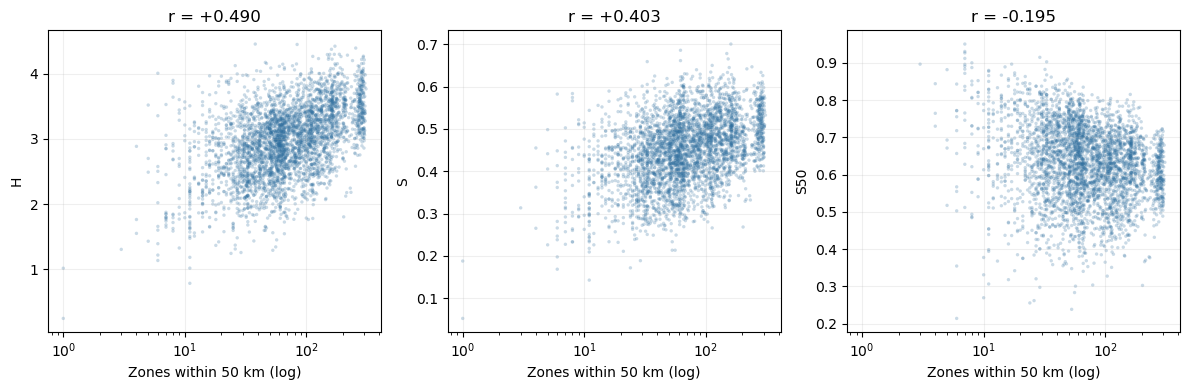

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True)
for ax, name in zip(axes, ["H", "S", "S50"]):
    x = e[["n_avail", name]].dropna()
    x = x[x["n_avail"] > 0]
    ax.scatter(x["n_avail"], x[name], s=6, alpha=0.25, color="#2f6f9f", edgecolors="none")
    ax.set_xscale("log")
    ax.set_xlabel("Zones within 50 km (log)")
    ax.set_ylabel(name)
    r = np.corrcoef(np.log(x["n_avail"]), x[name])[0, 1]
    ax.set_title(f"r = {r:+.3f}")
    ax.grid(alpha=0.2)

fig.tight_layout()
save(fig, "s50_defense_scatter.png", "s50_defense")
plt.show()

## Including same-zone trips

The cached matrix above has zero self-loops (dropped when it was built). Rebuilding
from the raw source with `id_origin == id_destination` kept — a district where
everyone stays home should not look identical to one where everyone commutes out.

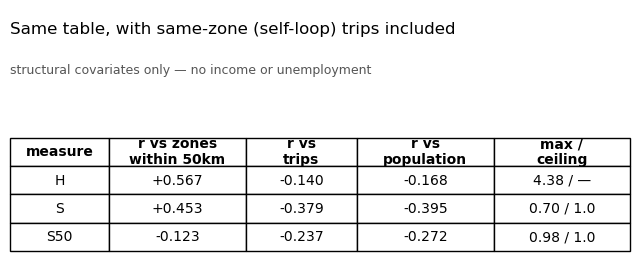

In [14]:
pairs_pii = pd.read_parquet(
    DATA / "recent_2025-03" / "Viajes_distritos_2025-03_v2.parquet",
    columns=["id_origin", "id_destination", "n_trips"],
)
pairs_pii = (
    pairs_pii.groupby(["id_origin", "id_destination"], as_index=False)["n_trips"].sum()
)
pairs_pii[["id_origin", "id_destination"]] = pairs_pii[["id_origin", "id_destination"]].astype(str)
pairs_pii = pairs_pii[
    pairs_pii["id_origin"].str[0].str.isdigit()
    & pairs_pii["id_destination"].str[0].str.isdigit()
    & (pairs_pii["n_trips"] > 0)
]

totals_pii = pairs_pii.groupby("id_origin")["n_trips"].transform("sum")
p_pii = pairs_pii["n_trips"] / totals_pii
H_pii = (
    pairs_pii.assign(term=-p_pii * np.log(p_pii))
    .groupby("id_origin")["term"].sum()
)

# `within` already includes each zone paired with itself (query_ball_point returns
# the point itself), so no need to add self-pairs separately here.
local_pii = pairs_pii.merge(within, on=["id_origin", "id_destination"])
local_pii_totals = local_pii.groupby("id_origin")["n_trips"].transform("sum")
q_pii = local_pii["n_trips"] / local_pii_totals
H50_pii = (
    local_pii.assign(term=-q_pii * np.log(q_pii))
    .groupby("id_origin")["term"].sum()
)

e_pii = pd.DataFrame({
    "H": H_pii,
    "S": H_pii / np.log(pairs_pii.groupby("id_origin")["id_destination"].nunique()),
    "S50": H50_pii / np.log(entropy["n_avail"] + 1),  # +1: self-zone now counts as an available destination
    "n_avail": entropy["n_avail"],
    "trips": pairs_pii.groupby("id_origin")["n_trips"].sum(),
    "population": entropy["population"],
})
e_pii = e_pii.replace([np.inf, -np.inf], np.nan)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.axis("off")
ax.text(0, 0.95, "Same table, with same-zone (self-loop) trips included", fontsize=12, va="top")
ax.text(0, 0.78, "structural covariates only — no income or unemployment", fontsize=9, va="top", color="#555555")

rows_pii = []
for name in ["H", "S", "S50"]:
    x = e_pii[["n_avail", "trips", "population", name]].dropna()
    x = x[(x["n_avail"] > 0) & (x["trips"] > 0) & (x["population"] > 0)]
    ceiling = "—" if name == "H" else "1.0"
    rows_pii.append([
        name,
        f"{np.corrcoef(np.log(x['n_avail']), x[name])[0,1]:+.3f}",
        f"{np.corrcoef(np.log(x['trips']), x[name])[0,1]:+.3f}",
        f"{np.corrcoef(np.log(x['population']), x[name])[0,1]:+.3f}",
        f"{e_pii[name].max():.2f} / {ceiling}",
    ])

table = ax.table(
    cellText=rows_pii,
    colLabels=["measure", "r vs zones\nwithin 50km", "r vs\ntrips", "r vs\npopulation", "max /\nceiling"],
    cellLoc="center",
    loc="lower center",
    colWidths=[0.16, 0.22, 0.18, 0.22, 0.22],
)
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.7)
for j in range(5):
    table[0, j].set_text_props(weight="bold")

save(fig, "s50_defense_table_with_pii.png", "s50_defense")
plt.show()

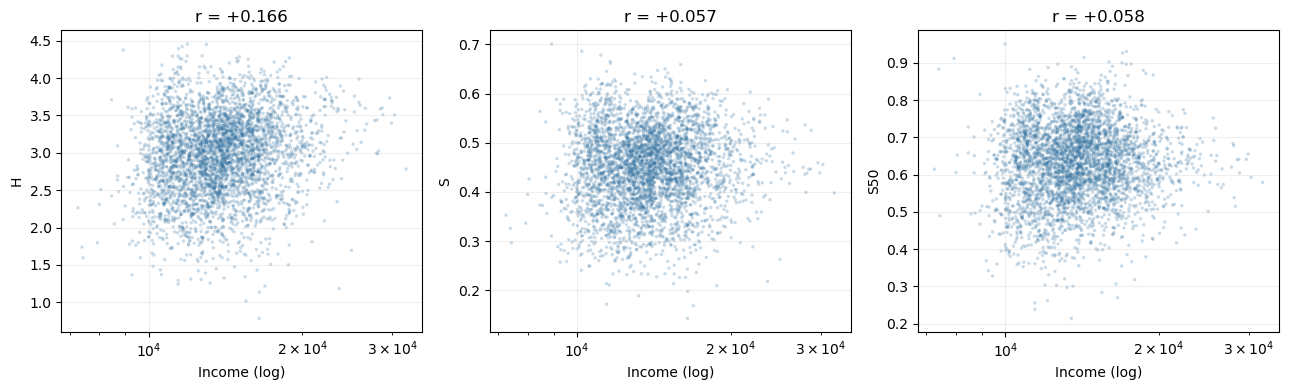

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, ["H", "S", "S50"]):
    x = c[["income", col]].dropna()
    ax.scatter(x["income"], x[col], s=6, alpha=0.25, color="#2f6f9f", edgecolors="none")
    ax.set_xscale("log")
    ax.set_xlabel("Income (log)")
    ax.set_ylabel(col)
    ax.set_title(f"r = {np.corrcoef(np.log(x['income']), x[col])[0, 1]:+.3f}")
    ax.grid(alpha=0.2)

fig.tight_layout()
save(fig, "income_direct_H_S_S50.png", "measure1")
plt.show()

## S50 against income

Same regression as H, with the geographic dependence normalised out of the measure.

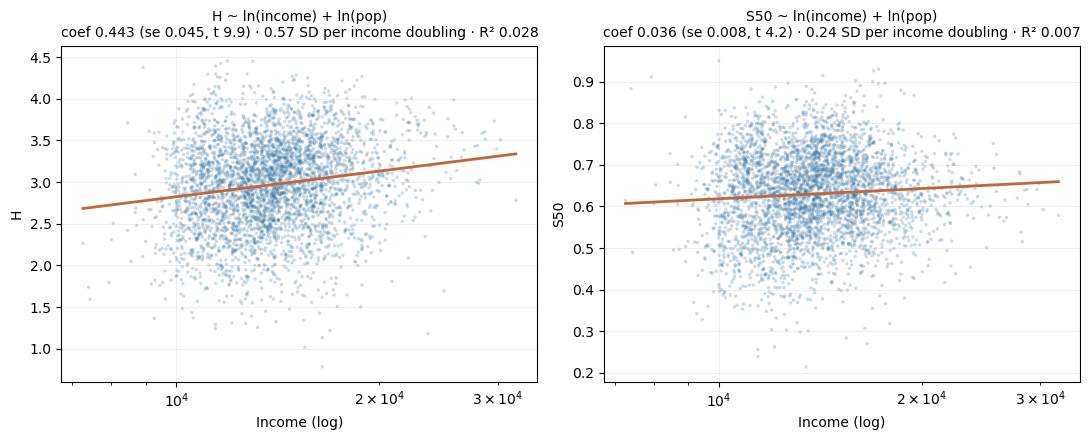

H    n=3,738  R2=0.0277  income coef=0.4428 (se 0.0446, t 9.92)
      effect of doubling income: 0.3069 = 0.571 SD of H
S50  n=3,738  R2=0.0068  income coef=0.0355 (se 0.0085, t 4.19)
      effect of doubling income: 0.0246 = 0.244 SD of S50


In [16]:
reg = c.dropna(subset=["S50", "income", "pop"])
X = sm.add_constant(pd.DataFrame({"log_income": np.log(reg["income"]), "log_pop": np.log(reg["pop"])}))
models = {m: sm.OLS(reg[m], X).fit() for m in ["H", "S50"]}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, fit) in zip(axes, models.items()):
    ax.scatter(reg["income"], reg[name], s=6, alpha=0.25, color="#2f6f9f", edgecolors="none")
    grid = np.linspace(reg["income"].min(), reg["income"].max(), 100)
    ax.plot(
        grid,
        fit.params["const"]
        + fit.params["log_income"] * np.log(grid)
        + fit.params["log_pop"] * np.log(reg["pop"]).mean(),
        color="#c1663a",
        lw=2,
    )
    ax.set_xscale("log")
    ax.set_xlabel("Income (log)")
    ax.set_ylabel(name)
    b, se = fit.params["log_income"], fit.bse["log_income"]
    sd = reg[name].std()
    ax.set_title(
        f"{name} ~ ln(income) + ln(pop)\n"
        f"coef {b:.3f} (se {se:.3f}, t {b / se:.1f}) · "
        f"{b * np.log(2) / sd:.2f} SD per income doubling · R² {fit.rsquared:.3f}",
        fontsize=10,
    )
    ax.grid(alpha=0.2)

fig.tight_layout()
save(fig, "regression_S50_vs_H_income.png", "measure1")
plt.show()

for name, fit in models.items():
    b, se = fit.params["log_income"], fit.bse["log_income"]
    print(f"{name:4s} n={int(fit.nobs):,}  R2={fit.rsquared:.4f}  income coef={b:.4f} (se {se:.4f}, t {b/se:.2f})")
    print(f"      effect of doubling income: {b * np.log(2):.4f} = {b * np.log(2) / reg[name].std():.3f} SD of {name}")

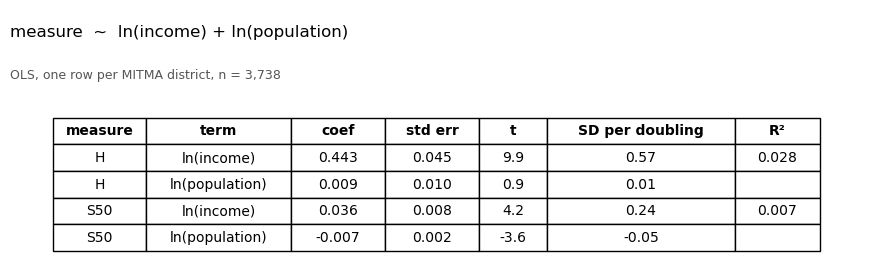

--- H · n = 3,738 · R2 = 0.0277
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.3356      0.418     -3.197      0.001      -2.155      -0.516
log_income     0.4428      0.045      9.924      0.000       0.355       0.530
log_pop        0.0092      0.010      0.881      0.378      -0.011       0.030
--- S50 · n = 3,738 · R2 = 0.0068
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.3557      0.079      4.484      0.000       0.200       0.511
log_income     0.0355      0.008      4.194      0.000       0.019       0.052
log_pop       -0.0072      0.002     -3.601      0.000      -0.011      -0.003


In [17]:
rows = []
for name, fit in models.items():
    sd = reg[name].std()
    for term, label in [("log_income", "ln(income)"), ("log_pop", "ln(population)")]:
        b, se = fit.params[term], fit.bse[term]
        rows.append([
            name,
            label,
            f"{b:.3f}",
            f"{se:.3f}",
            f"{b / se:.1f}",
            f"{b * np.log(2) / sd:.2f}",
            f"{fit.rsquared:.3f}" if term == "log_income" else "",
        ])

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.axis("off")
ax.text(0, 0.94, "measure  ~  ln(income) + ln(population)", fontsize=12, va="top")
ax.text(0, 0.76, f"OLS, one row per MITMA district, n = {int(models['H'].nobs):,}", fontsize=9, va="top", color="#555555")

table = ax.table(
    cellText=rows,
    colLabels=["measure", "term", "coef", "std err", "t", "SD per doubling", "R²"],
    cellLoc="center",
    loc="lower center",
    colWidths=[0.11, 0.17, 0.11, 0.11, 0.08, 0.22, 0.10],
)
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.6)
for j in range(7):
    table[0, j].set_text_props(weight="bold")

save(fig, "regression_S50_table.png", "measure1")
plt.show()

for name, fit in models.items():
    print(f"--- {name} · n = {int(fit.nobs):,} · R2 = {fit.rsquared:.4f}")
    print(fit.summary().tables[1])

# Measure 2b — income diversity of arrivals

Entropy over the income bands of people arriving at each destination. Three bands
(<10k, 10-15k, >15k EUR/yr), so the maximum is `ln 3` for every zone -- no
geography-dependent denominator.


In [18]:
import pyarrow.dataset as ds

BANDS = ["<10", "10-15", ">15"]

arrivals = (
    ds.dataset(DATA / "recent_2025-03" / "Viajes_distritos_2025-03_age_income_v2.parquet")
    .to_table(columns=["destino", "origen", "renta", "n_trips"])
    .to_pandas()
)
arrivals = arrivals[
    arrivals["destino"].str[0].str.isdigit()
    & arrivals["origen"].str[0].str.isdigit()
    & (arrivals["destino"] != arrivals["origen"])
    & (arrivals["n_trips"] > 0)
]
arrivals = (
    arrivals.groupby(["destino", "renta"])["n_trips"].sum()
    .unstack("renta")
    .reindex(columns=BANDS)
    .fillna(0.0)
)

totals = arrivals.sum(axis=1)
p = arrivals.div(totals, axis=0)

entropy["D"] = -(p * np.log(p.where(p > 0))).sum(axis=1) / np.log(3)
entropy["trips_in"] = totals

print(f"{entropy['D'].notna().sum():,} destinations")
print(entropy["D"].describe()[["min", "25%", "50%", "75%", "max"]].round(3).to_string())
print()
print("mean band shares:", p.mean().round(3).to_dict())


3,742 destinations
min    0.041
25%    0.273
50%    0.439
75%    0.598
max    0.996

mean band shares: {'<10': 0.179, '10-15': 0.67, '>15': 0.15}


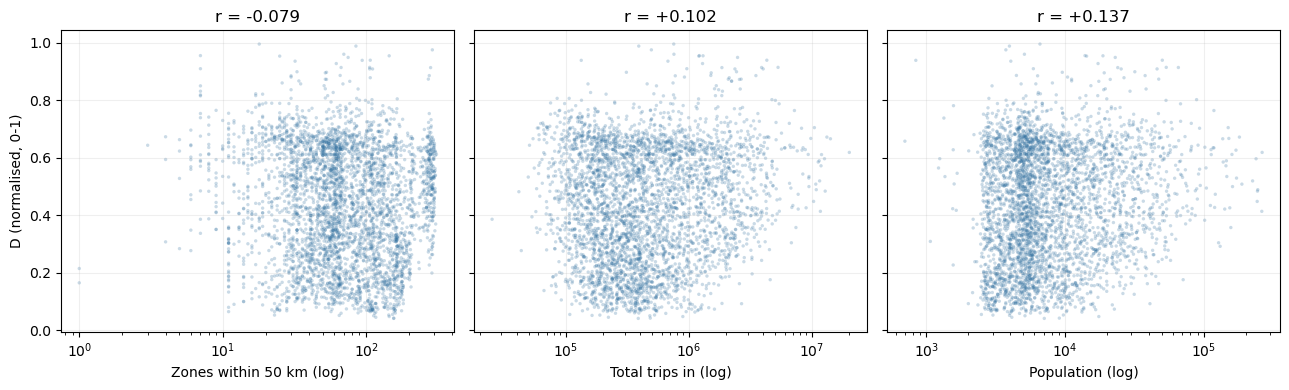

In [19]:
panels = [
    ("n_avail", "Zones within 50 km (log)"),
    ("trips_in", "Total trips in (log)"),
    ("population", "Population (log)"),
]

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (col, label) in zip(axes, panels):
    x = entropy[[col, "D"]].dropna()
    x = x[x[col] > 0]
    ax.scatter(x[col], x["D"], s=6, alpha=0.25, color="#2f6f9f", edgecolors="none")
    ax.set_xscale("log")
    ax.set_xlabel(label)
    ax.set_title(f"r = {np.corrcoef(np.log(x[col]), x['D'])[0, 1]:+.3f}")
    ax.grid(alpha=0.2)

axes[0].set_ylabel("D (normalised, 0-1)")
fig.tight_layout()
save(fig, "income_diversity_confounds.png", "income_diversity")
plt.show()


## The regression: SES against entropy, with controls

We now flip direction: income and unemployment are the outcomes, entropy is the
predictor. Covariates soak up factors that aren't about socioeconomic status —
district area, how many zones are nearby, and how much travel happens at all.
Province fixed effects give each province its own intercept, absorbing regional
differences (cost of living, regional economy) that aren't in our covariates.

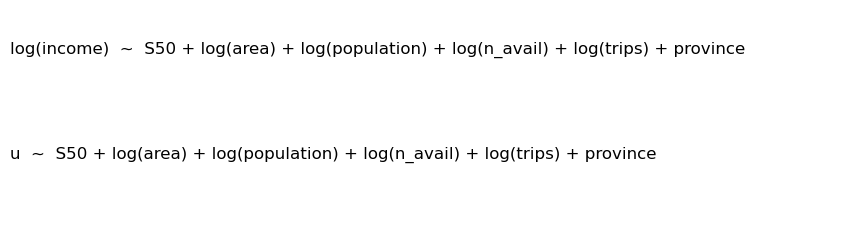

In [20]:
fig, ax = plt.subplots(figsize=(9, 2.4))
ax.axis("off")

ax.text(0, 0.85, "log(income)  ~  S50 + log(area) + log(population) + log(n_avail) + log(trips) + province", fontsize=12, va="top")
ax.text(0, 0.35, "u  ~  S50 + log(area) + log(population) + log(n_avail) + log(trips) + province", fontsize=12, va="top")

fig.tight_layout()
save(fig, "formula_ses_regression.png", "ses_formula")
plt.show()

In [21]:
import statsmodels.formula.api as smf

log_area = np.log(zones.geometry.area).rename("log_area")
province = pd.Series(zones.index.str[:2], index=zones.index, name="province")

covariates = pd.DataFrame({"log_area": log_area, "province": province})
covariates["log_n_avail"] = np.log(entropy["n_avail"])
covariates["log_trips"] = np.log(entropy["trips"])
covariates["log_pop"] = np.log(entropy["population"])

reg2 = reg.join(covariates).dropna(subset=["log_area", "log_pop", "log_n_avail", "log_trips", "province"])

income_model = smf.ols(
    "np.log(income) ~ S50 + log_area + log_pop + log_n_avail + log_trips + C(province)",
    data=reg2,
).fit()

reg3 = reg2.join(u["u"]).dropna(subset=["u"])
unemployment_model = smf.ols(
    "u ~ S50 + log_area + log_pop + log_n_avail + log_trips + C(province)",
    data=reg3,
).fit()

print(f"income model:      n={int(income_model.nobs):,}  R2={income_model.rsquared:.3f}")
print(f"unemployment model: n={int(unemployment_model.nobs):,}  R2={unemployment_model.rsquared:.3f}")

income model:      n=3,738  R2=0.582
unemployment model: n=3,267  R2=0.540


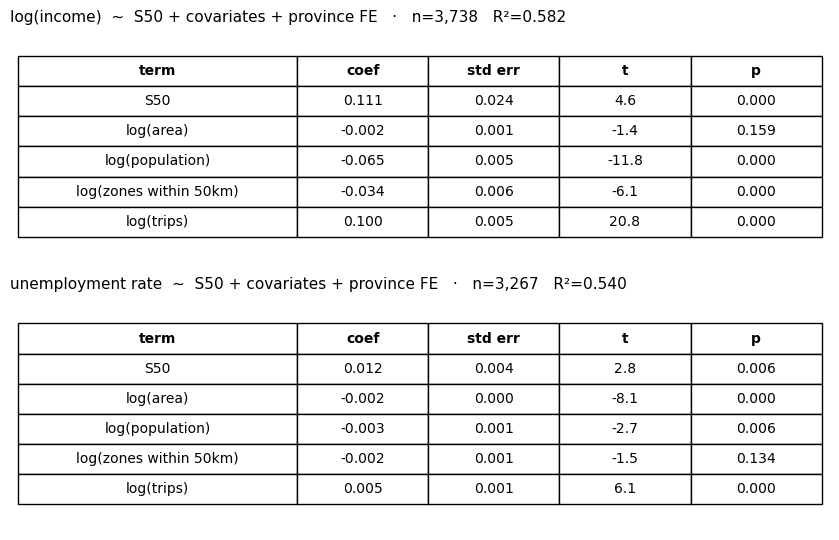

S50            1.09
log_area       1.51
log_pop        4.20
log_n_avail    1.33
log_trips      4.95


In [22]:
def coef_table(fit, terms, labels):
    rows = []
    for term, label in zip(terms, labels):
        b, se, p = fit.params[term], fit.bse[term], fit.pvalues[term]
        rows.append([label, f"{b:.3f}", f"{se:.3f}", f"{b / se:.1f}", f"{p:.3f}"])
    return rows


TERMS = ["S50", "log_area", "log_pop", "log_n_avail", "log_trips"]
LABELS = ["S50", "log(area)", "log(population)", "log(zones within 50km)", "log(trips)"]

fig, axes = plt.subplots(2, 1, figsize=(8.5, 5.5))
for ax, (name, fit) in zip(axes, [("log(income)", income_model), ("unemployment rate", unemployment_model)]):
    ax.axis("off")
    ax.set_title(
        f"{name}  ~  S50 + covariates + province FE   ·   n={int(fit.nobs):,}   R²={fit.rsquared:.3f}",
        fontsize=11, loc="left",
    )
    table = ax.table(
        cellText=coef_table(fit, TERMS, LABELS),
        colLabels=["term", "coef", "std err", "t", "p"],
        cellLoc="center", loc="center",
        colWidths=[0.34, 0.16, 0.16, 0.16, 0.16],
    )
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1, 1.5)
    for j in range(5):
        table[0, j].set_text_props(weight="bold")

fig.tight_layout()
save(fig, "ses_regression_tables.png", "ses_formula")
plt.show()

from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = sm.add_constant(reg2[["S50", "log_area", "log_pop", "log_n_avail", "log_trips"]])
vif = pd.Series(
    [variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])],
    index=X_vif.columns[1:],
    name="VIF",
)
print(vif.round(2).to_string())

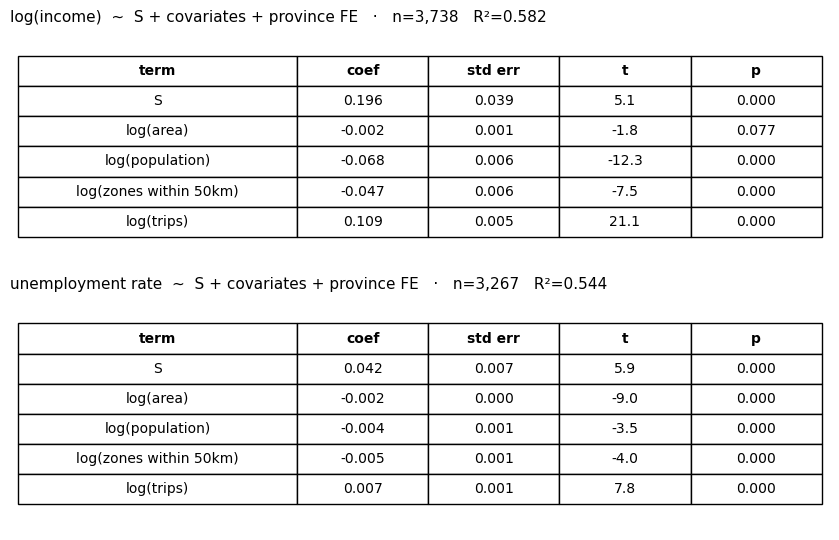

In [23]:
reg2_S = c.dropna(subset=["S", "income", "pop"]).join(covariates).dropna(
    subset=["log_area", "log_pop", "log_n_avail", "log_trips", "province"]
)
income_model_S = smf.ols(
    "np.log(income) ~ S + log_area + log_pop + log_n_avail + log_trips + C(province)",
    data=reg2_S,
).fit()

reg3_S = reg2_S.join(u["u"]).dropna(subset=["u"])
unemployment_model_S = smf.ols(
    "u ~ S + log_area + log_pop + log_n_avail + log_trips + C(province)",
    data=reg3_S,
).fit()

TERMS_S = ["S", "log_area", "log_pop", "log_n_avail", "log_trips"]
LABELS_S = ["S", "log(area)", "log(population)", "log(zones within 50km)", "log(trips)"]

fig, axes = plt.subplots(2, 1, figsize=(8.5, 5.5))
for ax, (name, fit) in zip(axes, [("log(income)", income_model_S), ("unemployment rate", unemployment_model_S)]):
    ax.axis("off")
    ax.set_title(
        f"{name}  ~  S + covariates + province FE   ·   n={int(fit.nobs):,}   R²={fit.rsquared:.3f}",
        fontsize=11, loc="left",
    )
    table = ax.table(
        cellText=coef_table(fit, TERMS_S, LABELS_S),
        colLabels=["term", "coef", "std err", "t", "p"],
        cellLoc="center", loc="center",
        colWidths=[0.34, 0.16, 0.16, 0.16, 0.16],
    )
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1, 1.5)
    for j in range(5):
        table[0, j].set_text_props(weight="bold")

fig.tight_layout()
save(fig, "ses_regression_tables_S.png", "ses_formula")
plt.show()

## Income exposure — do people travel to similar-income areas?

`I_i`: trip-weighted average income of an origin's destinations (excluding self-loops
— staying home says nothing about other areas). If people mostly travel to
similar-income places, `I` should track own income closely.

Income also clusters geographically on its own — rich districts tend to border rich
districts — so before trusting `I`, we build a separate control: `income_nbr`, the
plain average income of districts that physically share a border (queen contiguity,
no trips involved). This tells us how much of `I` is just "I'm surrounded by
similar income" versus something about travel behavior itself.

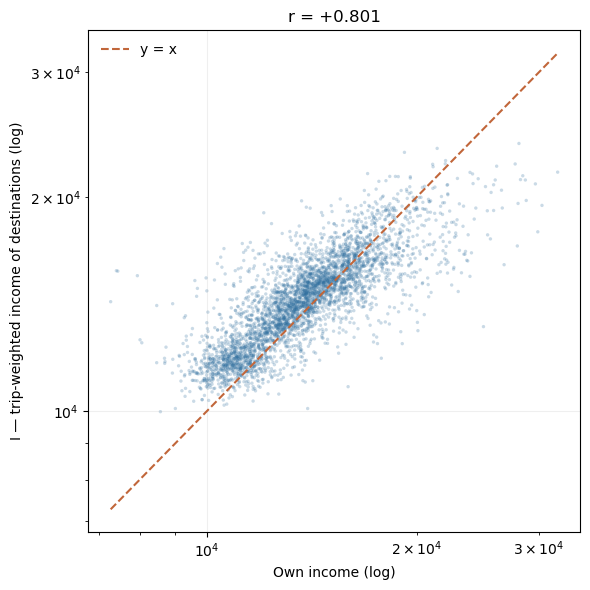

min     9972.0
50%    14333.0
max    23803.0


In [24]:
dest_income = pairs.merge(districts["income"], left_on="id_destination", right_index=True)
dest_income = dest_income[dest_income["income"] > 0]

w = dest_income["n_trips"] / dest_income.groupby("id_origin")["n_trips"].transform("sum")
I = (dest_income["income"] * w).groupby(dest_income["id_origin"]).sum()

exposure = d[["income"]].join(I.rename("I")).dropna()

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(exposure["income"], exposure["I"], s=6, alpha=0.25, color="#2f6f9f", edgecolors="none")
lims = [exposure[["income", "I"]].min().min(), exposure[["income", "I"]].max().max()]
ax.plot(lims, lims, color="#c1663a", lw=1.5, ls="--", label="y = x")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Own income (log)")
ax.set_ylabel("I — trip-weighted income of destinations (log)")
r = np.corrcoef(np.log(exposure["income"]), np.log(exposure["I"]))[0, 1]
ax.set_title(f"r = {r:+.3f}")
ax.legend(frameon=False)
ax.grid(alpha=0.2)
fig.tight_layout()
save(fig, "income_exposure_vs_own_income.png", "ses_formula")
plt.show()

print(exposure["I"].describe()[["min", "50%", "max"]].round(0).to_string())

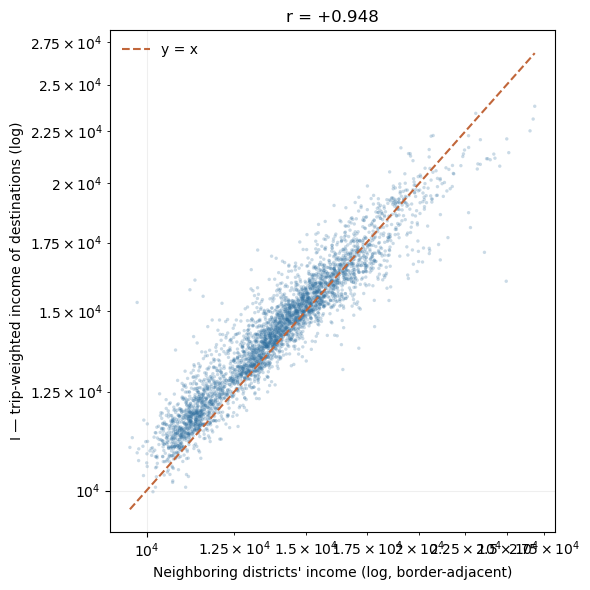

own income  vs I:      r = +0.801
neighbor income vs I:  r = +0.948
own income vs neighbor income: r = +0.833


In [25]:
from libpysal.weights import Queen

zones_income = zones.join(districts["income"])
zones_income = zones_income[zones_income["income"] > 0]

wq = Queen.from_dataframe(zones_income, use_index=True, silence_warnings=True)
neighbor_income = pd.Series(
    {
        idx: zones_income["income"].loc[list(wq.neighbors[idx])].mean()
        for idx in zones_income.index
        if wq.neighbors[idx]
    },
    name="income_nbr",
)

exposure = exposure.join(neighbor_income).dropna()

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(exposure["income_nbr"], exposure["I"], s=6, alpha=0.25, color="#2f6f9f", edgecolors="none")
lims = [exposure[["income_nbr", "I"]].min().min(), exposure[["income_nbr", "I"]].max().max()]
ax.plot(lims, lims, color="#c1663a", lw=1.5, ls="--", label="y = x")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Neighboring districts' income (log, border-adjacent)")
ax.set_ylabel("I — trip-weighted income of destinations (log)")
r = np.corrcoef(np.log(exposure["income_nbr"]), np.log(exposure["I"]))[0, 1]
ax.set_title(f"r = {r:+.3f}")
ax.legend(frameon=False)
ax.grid(alpha=0.2)
fig.tight_layout()
save(fig, "income_exposure_vs_neighbor_income.png", "ses_formula")
plt.show()

print(f"own income  vs I:      r = {np.corrcoef(np.log(exposure['income']), np.log(exposure['I']))[0,1]:+.3f}")
print(f"neighbor income vs I:  r = {np.corrcoef(np.log(exposure['income_nbr']), np.log(exposure['I']))[0,1]:+.3f}")
print(f"own income vs neighbor income: r = {np.corrcoef(np.log(exposure['income']), np.log(exposure['income_nbr']))[0,1]:+.3f}")

## Correlation matrix — S regressions

Pairwise Pearson correlation between every variable in each model (S version, for
simplicity). Values run from -1 (perfectly opposite) to +1 (move perfectly
together); 0 means no linear relationship. This is not the regression itself —
it's a check on the inputs, useful for spotting variables that are redundant with
each other before trusting their individual coefficients.

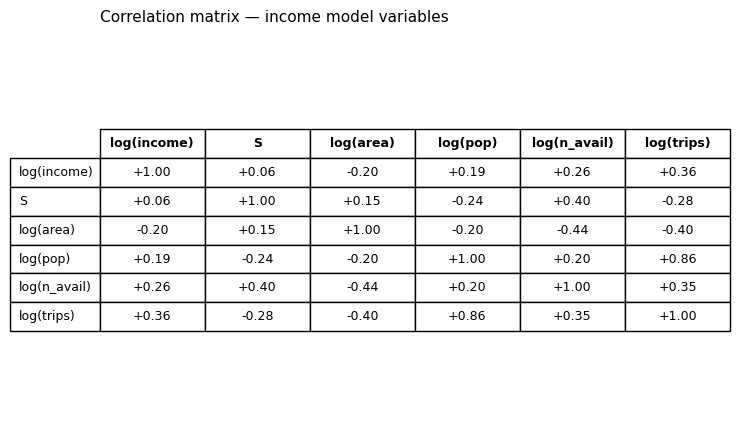

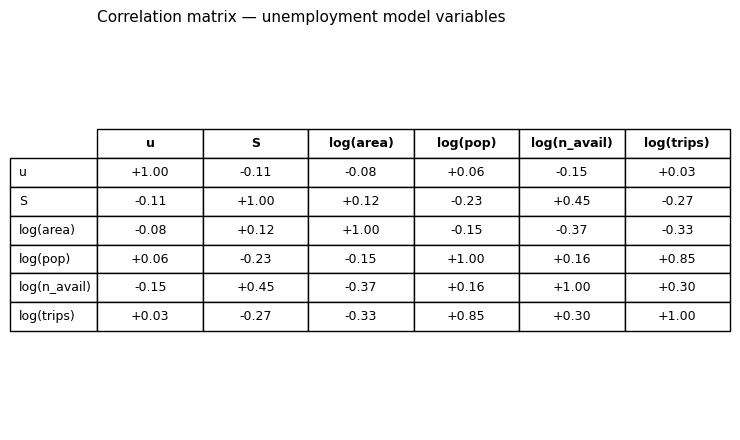

In [26]:
def corr_table(df, cols, labels, title):
    corr = df[cols].corr().to_numpy()
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    ax.axis("off")
    ax.set_title(title, fontsize=11, loc="left")
    table = ax.table(
        cellText=[[f"{v:+.2f}" for v in row] for row in corr],
        rowLabels=labels,
        colLabels=labels,
        cellLoc="center", loc="center",
    )
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1, 1.5)
    for j in range(len(labels)):
        table[0, j].set_text_props(weight="bold")
    fig.tight_layout()
    return fig


income_corr_df = reg2_S.assign(log_income=np.log(reg2_S["income"]))
fig = corr_table(
    income_corr_df,
    ["log_income", "S", "log_area", "log_pop", "log_n_avail", "log_trips"],
    ["log(income)", "S", "log(area)", "log(pop)", "log(n_avail)", "log(trips)"],
    "Correlation matrix — income model variables",
)
save(fig, "correlation_matrix_income.png", "ses_formula")
plt.show()

fig = corr_table(
    reg3_S,
    ["u", "S", "log_area", "log_pop", "log_n_avail", "log_trips"],
    ["u", "S", "log(area)", "log(pop)", "log(n_avail)", "log(trips)"],
    "Correlation matrix — unemployment model variables",
)
save(fig, "correlation_matrix_unemployment.png", "ses_formula")
plt.show()

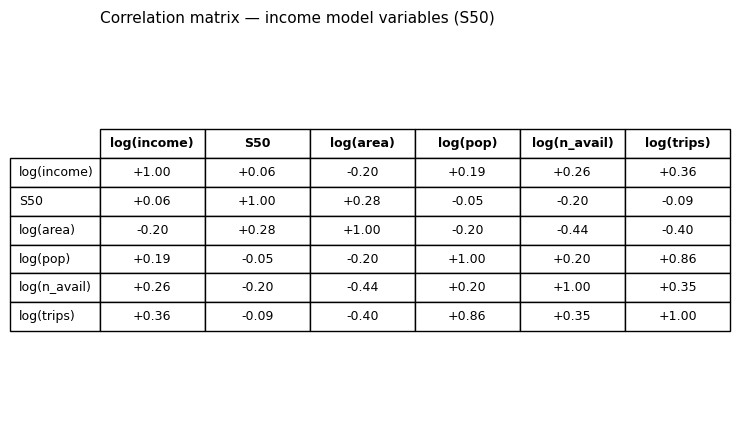

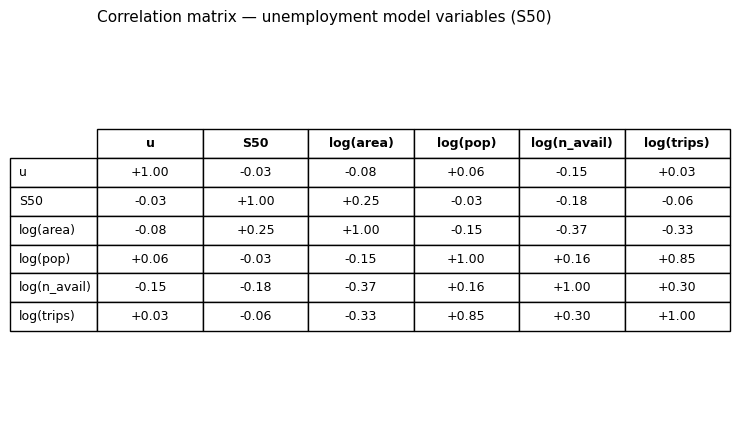

In [27]:
income_corr_df_S50 = reg2.assign(log_income=np.log(reg2["income"]))
fig = corr_table(
    income_corr_df_S50,
    ["log_income", "S50", "log_area", "log_pop", "log_n_avail", "log_trips"],
    ["log(income)", "S50", "log(area)", "log(pop)", "log(n_avail)", "log(trips)"],
    "Correlation matrix — income model variables (S50)",
)
save(fig, "correlation_matrix_income_S50.png", "ses_formula")
plt.show()

fig = corr_table(
    reg3,
    ["u", "S50", "log_area", "log_pop", "log_n_avail", "log_trips"],
    ["u", "S50", "log(area)", "log(pop)", "log(n_avail)", "log(trips)"],
    "Correlation matrix — unemployment model variables (S50)",
)
save(fig, "correlation_matrix_unemployment_S50.png", "ses_formula")
plt.show()